# SHOWZ, empresa de venta de entradas a eventos 
# Ayuda a optimizar los gastos de marqueting 
## OBJETIVOS 
### Como los clientes usan el servicio
### Cuando empiezan a comprar 
### Cuanto dinero aporta cada cliente a la compañia 
### Cuando los ingresos cubren el costo de adquisicion de clientes 

In [ ]:
# librerias para el proyecto 
import pandas as pd 
import numpy as np
import seaborn as sns
from scipy import stats as st 
import matplotlib.pyplot as plt

In [ ]:
# elección de librerias para elaborar el analisis 
costos = pd.read_csv('/datasets/costs_us.csv')
ordenes = pd.read_csv('/datasets/orders_log_us.csv')
visitas = pd.read_csv('/datasets/visits_log_us.csv')

In [ ]:
#primer acercamiento a los datos para encontrar las acciones necesarias para su procesamiento 
print(costos.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2542 entries, 0 to 2541
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   source_id  2542 non-null   int64  
 1   dt         2542 non-null   object 
 2   costs      2542 non-null   float64
dtypes: float64(1), int64(1), object(1)
memory usage: 59.7+ KB
None


In [ ]:
# conocer la estructura de las columnas y su contenido es fundamental pra tomar desiciones al limpiar los datos 
costos.head(5)

,source_id,dt,costs
0,1,2017-06-01,75.20
1,1,2017-06-02,62.25
2,1,2017-06-03,36.53
3,1,2017-06-04,55.00
4,1,2017-06-05,57.08


In [ ]:
# cambiar los datos a un formato adecuado permite so correcta manipulacion, ademas de acceder a las operaciones correctas para el anlisis 
costos['dt'] =pd.to_datetime(costos['dt'])

### En este data set, solo se cambio el tipo de dato en la columna 'dt', usando el metodo .to_datetime

In [ ]:
# primer acercamiento al DF
ordenes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50415 entries, 0 to 50414
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Buy Ts   50415 non-null  object 
 1   Revenue  50415 non-null  float64
 2   Uid      50415 non-null  uint64 
dtypes: float64(1), object(1), uint64(1)
memory usage: 1.2+ MB


In [ ]:
#Estrucutura 
ordenes.head(5)

,Buy Ts,Revenue,Uid
0,2017-06-01 00:10:00,17.00,10329302124590727494
1,2017-06-01 00:25:00,0.55,11627257723692907447
2,2017-06-01 00:27:00,0.37,17903680561304213844
3,2017-06-01 00:29:00,0.55,16109239769442553005
4,2017-06-01 07:58:00,0.37,14200605875248379450


In [ ]:
ordenes = ordenes.rename(columns={
    'Buy Ts': 'buy_timestamp',
    'Revenue': 'revenue',
    'Uid': 'uid'
})

In [ ]:
ordenes['buy_timestamp'] = pd.to_datetime(ordenes['buy_timestamp'])
ordenes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50415 entries, 0 to 50414
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   buy_timestamp  50415 non-null  datetime64[ns]
 1   revenue        50415 non-null  float64       
 2   uid            50415 non-null  uint64        
dtypes: datetime64[ns](1), float64(1), uint64(1)
memory usage: 1.2 MB


### En la primera exploración, encontramos nombres de columnas con mayusculas y espacios, se cambiaron al formato adecuado con el metodo .rename(), la columna 'buy_timestamp' presentaba un tipo incorrecto de dato, usando el metodo .to_datetime se tranformo al tipo correcto para su manipulacion posterior.

In [ ]:
#primer acercamiento 
visitas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 359400 entries, 0 to 359399
Data columns (total 5 columns):
 #   Column     Non-Null Count   Dtype 
---  ------     --------------   ----- 
 0   Device     359400 non-null  object
 1   End Ts     359400 non-null  object
 2   Source Id  359400 non-null  int64 
 3   Start Ts   359400 non-null  object
 4   Uid        359400 non-null  uint64
dtypes: int64(1), object(3), uint64(1)
memory usage: 13.7+ MB


In [ ]:
# estructura del DF
visitas.head()

,Device,End Ts,Source Id,Start Ts,Uid
0,touch,2017-12-20 17:38:00,4,2017-12-20 17:20:00,16879256277535980062
1,desktop,2018-02-19 17:21:00,2,2018-02-19 16:53:00,104060357244891740
2,touch,2017-07-01 01:54:00,5,2017-07-01 01:54:00,7459035603376831527
3,desktop,2018-05-20 11:23:00,9,2018-05-20 10:59:00,16174680259334210214
4,desktop,2017-12-27 14:06:00,3,2017-12-27 14:06:00,9969694820036681168


In [ ]:
visitas = visitas.rename(columns={
    'Device': 'device',
    'End Ts': 'end_timestamp',
    'Source Id': 'source_id',
    'Start Ts': 'start_timestamp',
    'Uid': 'uid'
})

In [ ]:
visitas['end_timestamp'] = pd.to_datetime(visitas['end_timestamp'])
visitas['start_timestamp'] = pd.to_datetime(visitas['start_timestamp'])
visitas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 359400 entries, 0 to 359399
Data columns (total 5 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   device           359400 non-null  object        
 1   end_timestamp    359400 non-null  datetime64[ns]
 2   source_id        359400 non-null  int64         
 3   start_timestamp  359400 non-null  datetime64[ns]
 4   uid              359400 non-null  uint64        
dtypes: datetime64[ns](2), int64(1), object(1), uint64(1)
memory usage: 13.7+ MB


### En este DF, el formato de los nombres de las columnas estaba mezclando mayusculas y espacios, se corrigio usando el metodo .rename(), de igual forma se corrigio al tipo de dato correcto las columnas 'end_timestamp' y 'start_timestamp'usando to_datetime().
### Ahora con los datos limpios y en formato correcto, es hora de comenzar con el analisis solicitado.

### Paso numero dos, trabajaremos con el DF, visitas para responder algunas preguentas durante el analisis a estos datos 

In [ ]:
visitas.head(5)

,device,end_timestamp,source_id,start_timestamp,uid
0,touch,2017-12-20 17:38:00,4,2017-12-20 17:20:00,16879256277535980062
1,desktop,2018-02-19 17:21:00,2,2018-02-19 16:53:00,104060357244891740
2,touch,2017-07-01 01:54:00,5,2017-07-01 01:54:00,7459035603376831527
3,desktop,2018-05-20 11:23:00,9,2018-05-20 10:59:00,16174680259334210214
4,desktop,2017-12-27 14:06:00,3,2017-12-27 14:06:00,9969694820036681168


In [ ]:
#Creación  de las columnas 'date', 'week' y 'month' 
visitas['date'] = visitas['start_timestamp'].dt.date
visitas['week'] = visitas['start_timestamp'].dt.to_period('W')
visitas['month'] = visitas['start_timestamp'].astype('datetime64[M]')

In [ ]:
#Numero de sesiones por dia, semana y mes 
usuarios_por_dia = visitas.groupby('date')['uid'].nunique()
usuarios_por_semana =visitas.groupby('week')['uid'].nunique()
usuarios_por_mes = visitas.groupby('month')['uid'].nunique()
print(usuarios_por_dia.count())
print(usuarios_por_semana.count())
print(usuarios_por_mes.count())

364
53
12


In [ ]:
#Numero de sesiones por dia, cuantas tinen cada ususario 
ndsessiones_por_dia = visitas.groupby('date').size()
ndsessiones_por_semana = visitas.groupby('week').size()
ndsessiones_por_mes = visitas.groupby('month').size()

print(ndsessiones_por_dia.mean())
print(ndsessiones_por_semana.mean())
print(ndsessiones_por_mes.mean())

987.3626373626373
6781.132075471698
29950.0


In [ ]:
# Creacion de la columna 'session_duration' 
visitas['session_duration'] = visitas['end_timestamp'] - visitas['start_timestamp']

In [ ]:
# Creacion de la columna 'session_duration_minutes'
visitas['session_duration_minutes'] = visitas['session_duration'].dt.total_seconds() / 60
print(visitas.groupby('uid')['session_duration_minutes'].mean().head(10))
print(visitas.groupby('uid')['session_duration_minutes'].min().head(10))
print(visitas.groupby('uid')['session_duration_minutes'].max().head(10))

uid
11863502262781      6.00
49537067089222      2.00
297729379853735     1.00
313578113262317    11.00
325320750514679     5.00
397399764396656     1.00
407573351275847     5.00
498809019029702     2.00
526778907996220    20.75
577434573913691     9.00
Name: session_duration_minutes, dtype: float64
uid
11863502262781     6.0
49537067089222     2.0
297729379853735    1.0
313578113262317    6.0
325320750514679    1.0
397399764396656    1.0
407573351275847    5.0
498809019029702    2.0
526778907996220    3.0
577434573913691    1.0
Name: session_duration_minutes, dtype: float64
uid
11863502262781      6.0
49537067089222      2.0
297729379853735     1.0
313578113262317    18.0
325320750514679     9.0
397399764396656     1.0
407573351275847     5.0
498809019029702     2.0
526778907996220    52.0
577434573913691    17.0
Name: session_duration_minutes, dtype: float64


In [ ]:
# lista de dias activos por usuarios 
dias_activos_por_usuario = visitas.groupby('uid')['date'].nunique()

In [ ]:
#calculo de primera y ultima visita por usuario 
primera_visita = visitas.groupby('uid').agg({'start_timestamp': 'min'})
ultima_visita = visitas.groupby('uid').agg({'start_timestamp': 'max'})
print(primera_visita.head(5))
print(ultima_visita.head(5))

                    start_timestamp
uid                                
11863502262781  2018-03-01 17:27:00
49537067089222  2018-02-06 15:55:00
297729379853735 2017-06-07 18:47:00
313578113262317 2017-09-18 22:49:00
325320750514679 2017-09-30 14:29:00
                    start_timestamp
uid                                
11863502262781  2018-03-01 17:27:00
49537067089222  2018-02-06 15:55:00
297729379853735 2017-06-07 18:47:00
313578113262317 2018-03-11 17:23:00
325320750514679 2018-02-26 12:33:00


In [ ]:
# cuantos usuarios regresan despues de du primera visita 
usuarios_que_regresan = dias_activos_por_usuario[dias_activos_por_usuario > 1]


In [ ]:
# Crear columna tipo_usuario
visitas['tipo_usuario'] = visitas['uid'].apply(
    lambda x: 'Recurrente' if x in usuarios_que_regresan.index else 'Nuevo'
)
duracion_por_tipo = visitas.groupby('tipo_usuario')['session_duration_minutes'].mean()
print(duracion_por_tipo)

tipo_usuario
Nuevo          8.442896
Recurrente    13.292469
Name: session_duration_minutes, dtype: float64


In [ ]:
# Estadísticas descriptivas detalladas
print(visitas['session_duration_minutes'].describe())

count    359400.000000
mean         10.717095
std          16.618796
min         -46.000000
25%           2.000000
50%           5.000000
75%          14.000000
max         711.000000
Name: session_duration_minutes, dtype: float64


In [ ]:
# Calcular días entre primera y última visita
dias_entre_visitas = ultima_visita - primera_visita
dias_entre_visitas.head(5)

,start_timestamp
uid,
11863502262781,0 days 00:00:00
49537067089222,0 days 00:00:00
297729379853735,0 days 00:00:00
313578113262317,173 days 18:34:00
325320750514679,148 days 22:04:00


In [ ]:
# Total de usuarios únicos
total_usuarios = visitas['uid'].nunique()

# Porcentaje de usuarios que regresan
porcentaje_regreso = (len(usuarios_que_regresan) / total_usuarios) * 100
print(f"Porcentaje de usuarios que regresan: {porcentaje_regreso:.2f}%")

Porcentaje de usuarios que regresan: 19.74%


In [ ]:
# Promedio de días activos por usuario
promedio_dias_activos = dias_activos_por_usuario.mean()
print(f"Promedio de días activos por usuario: {promedio_dias_activos:.2f}")

Promedio de días activos por usuario: 1.45


In [ ]:
# Solo para usuarios que regresan (más de 1 día activo)
dias_entre_visitas_usuarios_recurrentes = dias_entre_visitas.loc[usuarios_que_regresan.index]
intervalo_promedio = dias_entre_visitas_usuarios_recurrentes['start_timestamp'].dt.days.mean()
print(f"Intervalo promedio entre primera y última visita: {intervalo_promedio:.2f} días")

Intervalo promedio entre primera y última visita: 81.37 días


### Tenenmos un conteo por usuario en el cual diariamente de 364 sessiones, 54 semanales y 12 sesiones mensuales. 
### Tenenmos un promedio diario de sesiones de 987.3626373626373 .
### Tenemos un promedio semanal de sesiones de 6781.132075471698 .
### Y un promedio mensual de session de 29950.0 .
### El promedio de tiempo para un usuario nuevo  es de 8.442896 minutos.
### El promedio para un usuario recurrente es de 13.292469 minutos.
### Porcentaje de usuarios que regresan: 19.74% 

### Paso NUMERO 2.1  Ventas trabajar con el DF ordenes 

In [ ]:
# Exploración básica del DataFrame ordenes
print("Información general:")
print(ordenes.info())
print("\nPrimeras filas:")
print(ordenes.head())
print("\nEstadísticas descriptivas:")
print(ordenes.describe())

Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50415 entries, 0 to 50414
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   buy_timestamp  50415 non-null  datetime64[ns]
 1   revenue        50415 non-null  float64       
 2   uid            50415 non-null  uint64        
dtypes: datetime64[ns](1), float64(1), uint64(1)
memory usage: 1.2 MB
None

Primeras filas:
        buy_timestamp  revenue                   uid
0 2017-06-01 00:10:00    17.00  10329302124590727494
1 2017-06-01 00:25:00     0.55  11627257723692907447
2 2017-06-01 00:27:00     0.37  17903680561304213844
3 2017-06-01 00:29:00     0.55  16109239769442553005
4 2017-06-01 07:58:00     0.37  14200605875248379450

Estadísticas descriptivas:
            revenue           uid
count  50415.000000  5.041500e+04
mean       4.999647  9.098161e+18
std       21.818359  5.285742e+18
min        0.000000  3.135781e+14
25%     

In [ ]:
# Encontrar la fecha de primera visita  y la primera compra 
visitas.groupby('uid')['start_timestamp'].min()
ordenes.groupby('uid')['buy_timestamp'].min()

uid
313578113262317        2018-01-03 21:51:00
1575281904278712       2017-06-03 10:13:00
2429014661409475       2017-10-11 18:33:00
2464366381792757       2018-01-28 15:54:00
2551852515556206       2017-11-24 10:14:00
                               ...        
18445147675727495770   2017-11-24 09:03:00
18445407535914413204   2017-09-22 23:55:00
18445601152732270159   2018-03-26 22:54:00
18446156210226471712   2018-02-18 19:34:00
18446167067214817906   2017-10-17 10:16:00
Name: buy_timestamp, Length: 36523, dtype: datetime64[ns]

In [ ]:
#Obtener primer visita por usuario 
primer_visita = visitas.groupby('uid')['start_timestamp'].min().reset_index()
primer_visita.columns = ['uid', 'fecha_registro']

#Obtener la primera compra por usuario 
primera_compra = ordenes.groupby('uid')['buy_timestamp'].min().reset_index()
primera_compra.columns = ['uid', 'fecha_primera_compra']

#Unir con inner jaoin ( solo usuarios que tienen ambos )
conversion_reg_com = primera_visita.merge(primera_compra, on='uid')

In [ ]:
conversion_reg_com.head(5)

,uid,start_timestamp,fecha_primera_compra
0,313578113262317,2017-09-18 22:49:00,2018-01-03 21:51:00
1,1575281904278712,2017-06-03 10:13:00,2017-06-03 10:13:00
2,2429014661409475,2017-10-11 17:14:00,2017-10-11 18:33:00
3,2464366381792757,2018-01-27 20:10:00,2018-01-28 15:54:00
4,2551852515556206,2017-11-24 10:14:00,2017-11-24 10:14:00


In [ ]:
#Creacion de las columnas 'dia_registro' y 'primera_compra'
conversion_reg_com['dia_registro'] = conversion_reg_com['start_timestamp'].astype('datetime64[D]')
conversion_reg_com['primera_compra'] = conversion_reg_com['fecha_primera_compra'].astype('datetime64[D]')

In [ ]:
#Creacion de la columna 'dias_de_inicio' haciendo una resta con las columnas 'primeracompra' y 'dia_de_registro' para filtrar las cohortes
conversion_reg_com['dias_de_inicio'] = conversion_reg_com['primera_compra'] - conversion_reg_com['dia_registro']
conversion_reg_com['dias_de_inicio'].sort_values(ascending=True)

36522     0 days
21049     0 days
21046     0 days
21045     0 days
21043     0 days
          ...   
12143   357 days
24282   357 days
35081   358 days
31247   363 days
13783   363 days
Name: dias_de_inicio, Length: 36523, dtype: timedelta64[ns]

In [ ]:
#Filtrado de cohorte mismo dia 
conversion_mismo_dia = conversion_reg_com[conversion_reg_com['dias_de_inicio'] == '0 days']
print(f"Usuarios que compraron el mismo día: {len(conversion_mismo_dia)}")

Usuarios que compraron el mismo día: 25039


In [ ]:
#Filtrado de cohorte semanal 
conversion_semana = conversion_reg_com[
    (conversion_reg_com['dias_de_inicio'] >= pd.Timedelta(days=1)) & 
    (conversion_reg_com['dias_de_inicio'] <= pd.Timedelta(days=7))
]
print(f"Usuarios que compraron entre 1 y 7 días: {len(conversion_semana)}")

Usuarios que compraron entre 1 y 7 días: 4297


In [ ]:
#Filtrado de cohorte mensual 
conversion_mes = conversion_reg_com[
    (conversion_reg_com['dias_de_inicio'] >= pd.Timedelta(days=1)) &
    (conversion_reg_com['dias_de_inicio'] <= pd.Timedelta(days=30)) 
]
print(f"Usuarios que compraron entre 1 y 30 días: {len(conversion_mes)}")

Usuarios que compraron entre 1 y 30 días: 6550


In [ ]:
#Foltrado de cohorte trimestral
conversion_trimestre = conversion_reg_com[
    (conversion_reg_com['dias_de_inicio'] >= pd.Timedelta(days=1)) &
    (conversion_reg_com['dias_de_inicio'] <= pd.Timedelta(days=90))
]
print(f"Usuarios que compraron entre 1 y 90 dias: {len(conversion_trimestre)}")

Usuarios que compraron entre 1 y 90 dias: 8839


In [ ]:
#Filtrado de cohorte anual 
conversion_anual = conversion_reg_com[
    (conversion_reg_com['dias_de_inicio'] >= pd.Timedelta(days=1)) &
    (conversion_reg_com['dias_de_inicio'] <= pd.Timedelta(days=360))
]
print(f"Usuarios que compraron entre 1 y 360 dias: {len(conversion_anual)}")

Usuarios que compraron entre 1 y 360 dias: 11482


In [ ]:
#Encontrar el canal de marketing de cada usuario 
canal_por_usuario = visitas.groupby('uid')['source_id'].first().reset_index()
canal_por_usuario.columns = ['uid', 'canal_marketing']

In [ ]:
# Agregar canal a cada DataFrame de conversión
conversion_mismo_dia_canal = conversion_mismo_dia.merge(canal_por_usuario, on='uid')
conversion_semana_canal = conversion_semana.merge(canal_por_usuario, on='uid')
conversion_mes_canal = conversion_mes.merge(canal_por_usuario, on='uid')
conversion_trimestre_canal = conversion_trimestre.merge(canal_por_usuario, on='uid')
conversion_anual_canal = conversion_anual.merge(canal_por_usuario, on='uid')

In [ ]:
total_de_usuarios_por_canal = visitas.groupby('source_id')['uid'].nunique()
print("Total usuarios por canal:")
print(total_de_usuarios_por_canal)

Total usuarios por canal:
source_id
1     18999
2     26245
3     74756
4     83525
5     56974
6         6
7        34
9      9264
10     8067
Name: uid, dtype: int64


In [ ]:
# Contar conversiones por canal mismo día 
conversiones_por_canal_d= conversion_mismo_dia_canal.groupby('canal_marketing')['uid'].nunique().sort_values(ascending=False)
print("Conversiones por canal (mismo día):")
print(conversiones_por_canal_d.head(10))

Conversiones por canal (mismo día):
canal_marketing
4     6762
3     6532
5     5076
2     2568
1     2424
10     915
9      761
7        1
Name: uid, dtype: int64


In [ ]:
# Contar conversiones por canal mismo día como ejemplo
conversiones_por_canal_w = conversion_semana_canal.groupby('canal_marketing')['uid'].nunique().sort_values(ascending=False)
print("Conversiones por canal (semanal):")
print(conversiones_por_canal_w.head(10))

Conversiones por canal (semanal):
canal_marketing
4     1107
3      967
5      683
2      627
1      614
9      163
10     136
Name: uid, dtype: int64


In [ ]:
# Contar conversiones por canal mensual
conversiones_por_canal_m = conversion_mes_canal.groupby('canal_marketing')['uid'].nunique().sort_values(ascending=False)
print("Conversiones por canal (mensual):")
print(conversiones_por_canal_m.head(10))

Conversiones por canal (mensual):
canal_marketing
4     1717
3     1463
5     1017
2      988
1      870
9      295
10     200
Name: uid, dtype: int64


In [ ]:
# Contar conversiones por canal anual
conversiones_por_canal_y = conversion_anual_canal.groupby('canal_marketing')['uid'].nunique().sort_values(ascending=False)
print("Conversiones por canal (anual):")
print(conversiones_por_canal_y.head(10))

Conversiones por canal (anual):
canal_marketing
4     3061
3     2606
5     1762
2     1755
1     1318
9      654
10     326
Name: uid, dtype: int64


In [ ]:
# Definir los canales principales basándote en los resultados
canales_principales = [4, 3, 5]  # Los 3 canales con más conversiones

# Calcular tasas de conversión para los canales principales
tasa_conversion_mismo_dia = []
tasa_conversion_semanal = []
tasa_conversion_mensual = []
tasa_conversion_anual = []

for canal in canales_principales:
    # Usuarios totales del canal
    total_usuarios_canal = total_de_usuarios_por_canal[canal]
    
    # Conversiones por período
    conv_dia = conversiones_por_canal_d.get(canal, 0)
    conv_semana = conversiones_por_canal_w.get(canal, 0)
    conv_mes = conversiones_por_canal_m.get(canal, 0)
    conv_anual = conversiones_por_canal_y.get(canal, 0)
    
    # Calcular tasas (en porcentaje)
    tasa_conversion_mismo_dia.append((conv_dia / total_usuarios_canal) * 100)
    tasa_conversion_semanal.append((conv_semana / total_usuarios_canal) * 100)
    tasa_conversion_mensual.append((conv_mes / total_usuarios_canal) * 100)
    tasa_conversion_anual.append((conv_anual / total_usuarios_canal) * 100)


In [ ]:
# Crear DataFrame con los resultados
resultados_canal = pd.DataFrame({
    'Canal': canales_principales,
    'Mismo_dia_%': [round(x, 2) for x in tasa_conversion_mismo_dia],
    'Semanal_%': [round(x, 2) for x in tasa_conversion_semanal], 
    'Mensual_%': [round(x, 2) for x in tasa_conversion_mensual],
})

print(resultados_canal)

   Canal  Mismo_dia_%  Semanal_%  Mensual_%
0      4         8.10       1.33       2.06
1      3         8.74       1.29       1.96
2      5         8.91       1.20       1.79


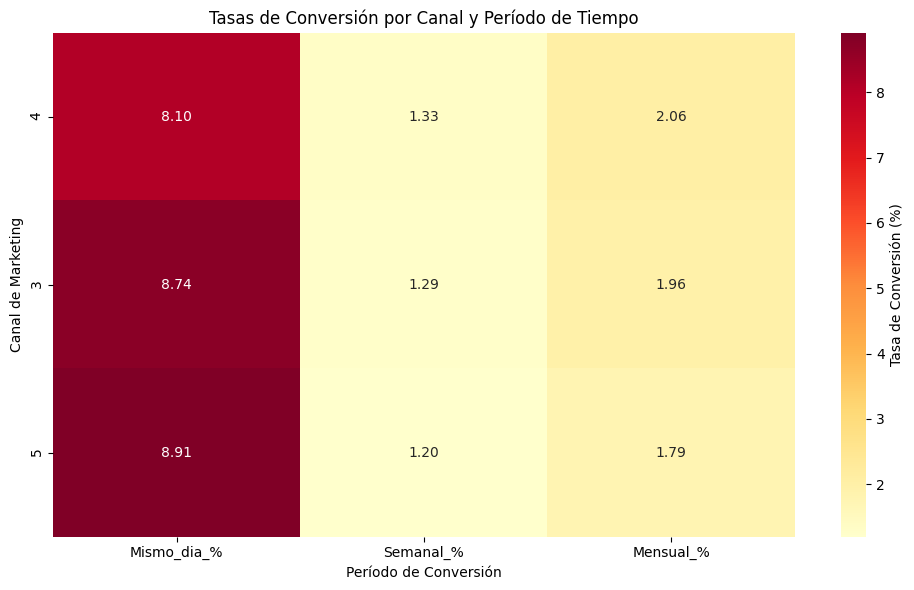

In [ ]:
# Preparar los datos para el heatmap
# Crear una matriz con los canales como filas y períodos como columnas
datos_heatmap = resultados_canal.set_index('Canal')[['Mismo_dia_%', 'Semanal_%', 'Mensual_%']]

# Crear el heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(datos_heatmap, 
            annot=True,  # Mostrar los valores en cada celda
            cmap='YlOrRd',  # Paleta de colores (amarillo a rojo)
            fmt='.2f',  # Formato de los números
            cbar_kws={'label': 'Tasa de Conversión (%)'})

plt.title('Tasas de Conversión por Canal y Período de Tiempo')
plt.xlabel('Período de Conversión')
plt.ylabel('Canal de Marketing')
plt.tight_layout()
plt.show()

## PASO 2 Ventas 
### Data Frame ordenes 
#### 2.1 Se realizaron segmentos de tiempo juntando los Data Frame visitas y ordenes, para obtnenr listas diarias, semanales, mensuales, trimestrales y anuales, se tomaron en cuenta solo 4 de elllas, diaria, semanal, mensual y anual, ya que la trimestral no arrojaba datos tan relebantes.
#### En el registro diario obtubimos un relstado favorable:  25039 personas que registraron y compraron.
#### En el registro semanal:  4297 , En el mensual: 6550 y en el Anual 11482.
#### De los canales disponbles para el registro y compra (10 en total que se encuentran en el Data Frame), se determino que los canales 4,3 y 5 son los mas efectivos para captar usuarios, destaca el canal 5 en el segmento diario, el numero 4 en el semanal, mensual y anual, el canal numero 3 se mantiene con metricas que compiten, pero quiza un pequeño impulso mediante una promocion o veneficio, podria ponerlo a la para en procentajes.

In [ ]:
pedidos_mismo_dia = conversion_mismo_dia_canal.merge(ordenes, on='uid')
print(pedidos_mismo_dia.head(5))

                uid     start_timestamp fecha_primera_compra dia_registro  \
0  1575281904278712 2017-06-03 10:13:00  2017-06-03 10:13:00   2017-06-03   
1  1575281904278712 2017-06-03 10:13:00  2017-06-03 10:13:00   2017-06-03   
2  2429014661409475 2017-10-11 17:14:00  2017-10-11 18:33:00   2017-10-11   
3  2551852515556206 2017-11-24 10:14:00  2017-11-24 10:14:00   2017-11-24   
4  2551852515556206 2017-11-24 10:14:00  2017-11-24 10:14:00   2017-11-24   

  primera_compra dias_de_inicio  canal_marketing       buy_timestamp  revenue  
0     2017-06-03         0 days               10 2017-06-03 10:13:00     1.22  
1     2017-06-03         0 days               10 2017-06-03 17:39:00     1.83  
2     2017-10-11         0 days                3 2017-10-11 18:33:00    73.33  
3     2017-11-24         0 days                5 2017-11-24 10:14:00     6.32  
4     2017-11-24         0 days                5 2017-11-24 11:24:00     4.67  


In [ ]:
pedidos_semanales = conversion_semana_canal.merge(ordenes, on='uid')
print(pedidos_semanales.head(5))

                 uid     start_timestamp fecha_primera_compra dia_registro  \
0   2464366381792757 2018-01-27 20:10:00  2018-01-28 15:54:00   2018-01-27   
1   9681021228476518 2017-12-07 23:53:00  2017-12-08 01:10:00   2017-12-07   
2  16969312487001837 2017-09-19 12:19:00  2017-09-20 10:39:00   2017-09-19   
3  18736772294992551 2017-11-27 22:53:00  2017-11-29 20:54:00   2017-11-27   
4  22538937500067142 2018-02-16 22:06:00  2018-02-19 13:09:00   2018-02-16   

  primera_compra dias_de_inicio  canal_marketing       buy_timestamp  revenue  
0     2018-01-28         1 days                5 2018-01-28 15:54:00     2.44  
1     2017-12-08         1 days                3 2017-12-08 01:10:00     1.83  
2     2017-09-20         1 days                4 2017-09-20 10:39:00     2.75  
3     2017-11-29         2 days                3 2017-11-29 20:54:00     2.75  
4     2018-02-19         3 days                1 2018-02-19 13:09:00     0.61  


In [ ]:
pedidos_mensuales = conversion_mes_canal.merge(ordenes, on='uid')
print(pedidos_semanales.head(5))


                 uid     start_timestamp fecha_primera_compra dia_registro  \
0   2464366381792757 2018-01-27 20:10:00  2018-01-28 15:54:00   2018-01-27   
1   9681021228476518 2017-12-07 23:53:00  2017-12-08 01:10:00   2017-12-07   
2  16969312487001837 2017-09-19 12:19:00  2017-09-20 10:39:00   2017-09-19   
3  18736772294992551 2017-11-27 22:53:00  2017-11-29 20:54:00   2017-11-27   
4  22538937500067142 2018-02-16 22:06:00  2018-02-19 13:09:00   2018-02-16   

  primera_compra dias_de_inicio  canal_marketing       buy_timestamp  revenue  
0     2018-01-28         1 days                5 2018-01-28 15:54:00     2.44  
1     2017-12-08         1 days                3 2017-12-08 01:10:00     1.83  
2     2017-09-20         1 days                4 2017-09-20 10:39:00     2.75  
3     2017-11-29         2 days                3 2017-11-29 20:54:00     2.75  
4     2018-02-19         3 days                1 2018-02-19 13:09:00     0.61  


In [ ]:
pedidos_anuales = conversion_anual_canal.merge(ordenes, on='uid')
print(pedidos_anuales.head(5))


                uid     start_timestamp fecha_primera_compra dia_registro  \
0   313578113262317 2017-09-18 22:49:00  2018-01-03 21:51:00   2017-09-18   
1  2464366381792757 2018-01-27 20:10:00  2018-01-28 15:54:00   2018-01-27   
2  3605148382144603 2017-08-15 21:54:00  2017-09-21 20:56:00   2017-08-15   
3  3605148382144603 2017-08-15 21:54:00  2017-09-21 20:56:00   2017-08-15   
4  3605148382144603 2017-08-15 21:54:00  2017-09-21 20:56:00   2017-08-15   

  primera_compra dias_de_inicio  canal_marketing       buy_timestamp  revenue  
0     2018-01-03       107 days                2 2018-01-03 21:51:00     0.55  
1     2018-01-28         1 days                5 2018-01-28 15:54:00     2.44  
2     2017-09-21        37 days                2 2017-09-21 20:56:00     0.12  
3     2017-09-21        37 days                2 2017-09-21 22:44:00     0.24  
4     2017-09-21        37 days                2 2017-09-21 23:52:00     0.33  


In [ ]:
pedidos_mismo_dia = conversion_mismo_dia_canal.merge(ordenes, on='uid')
total_pedidos_mismo_dia = len(pedidos_mismo_dia)
print(f"Total de pedidos mismo día: {total_pedidos_mismo_dia}")

Total de pedidos mismo día: 32334


In [ ]:
pedidos_semanal = conversion_semana_canal.merge(ordenes, on='uid')
total_pedidos_semanal = len(pedidos_semanal)
print(f"Total de pedidos semanales: {total_pedidos_semanal}")

Total de pedidos semanales: 7034


In [ ]:
pedidos_mensual = conversion_mes_canal.merge(ordenes, on='uid')
total_pedidos_mensual = len(pedidos_mensual)
print(f"Total de pedidos mensuales: {total_pedidos_mensual}")

Total de pedidos mensuales: 10861


#### 2.2 
### Tomando las mismas metricas, los pedidos diarios resaltan con una cantidad de 32334, en segundo lugar los mesuales con 10861, y en ultimo lugar los emanles con 7034.
### Es notable que las personas tienen la desicion de registrarse y comprar el mismo dia, esto debe suponer una buena imprecion y recomendacion de otros usuarios, y tomando en cuenta el flujo de los datos los clientes casi es su mayoria siguen usando la aplicacion despues de registrrse. 

In [ ]:
# Tamaño promedio de compra por cohorte
media_pedido_mismo_dia = pedidos_mismo_dia['revenue'].mean()
media_semanal = pedidos_semanal['revenue'].mean()
media_mensual = pedidos_mensual['revenue'].mean()

print("Media de pedidos diarios")
print(media_pedido_mismo_dia)
print("Media de pedidos por semana")
print(media_semanal)
print("Media pedidos mensual")
print(media_mensual)


Media de pedidos diarios
4.548547968083132
Media de pedidos por semana
5.033156098947967
Media pedidos mensual
6.0217153116655915


In [ ]:
# Tmaño mediana por cohorte 
mediana_pedido_mismo_dia = pedidos_mismo_dia['revenue'].median()
mediana_semanal = pedidos_semanal['revenue'].median()
mediana_mensual = pedidos_mensual['revenue'].median()

print("Mediana de pedidos diarios")
print(mediana_pedido_mismo_dia)
print("Mediana de pedidos por semana")
print(mediana_semanal)
print("Mediana pedidos mensual")
print(mediana_mensual)


Mediana de pedidos diarios
2.44
Mediana de pedidos por semana
2.69
Mediana pedidos mensual
2.75


In [ ]:
promedio_compra_por_usuario = ordenes.groupby('uid')['revenue'].mean()
print(promedio_compra_por_usuario.head(10))
print(promedio_compra_por_usuario.min())
print(promedio_compra_por_usuario.max())

uid
313578113262317      0.550
1575281904278712     1.525
2429014661409475    73.330
2464366381792757     2.440
2551852515556206     5.495
3077748354309989     4.670
3605148382144603     0.230
3753586865891862     3.500
4808417689019433     1.220
4992223027560440     3.050
Name: revenue, dtype: float64
0.0
657.4662500000001


In [ ]:
print(promedio_compra_por_usuario.describe())

count    36523.000000
mean         4.093093
std          7.671220
min          0.000000
25%          1.285000
50%          2.490000
75%          4.890000
max        657.466250
Name: revenue, dtype: float64


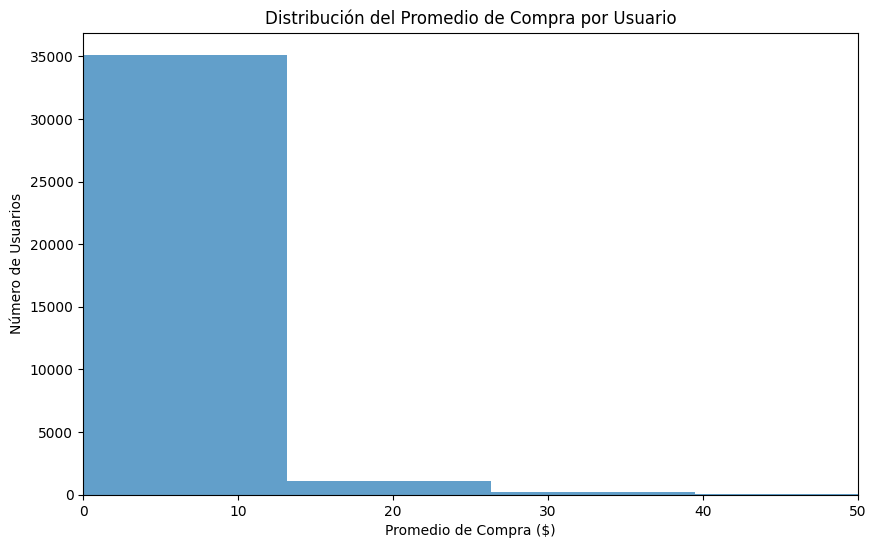

In [ ]:
plt.figure(figsize=(10, 6))
plt.hist(promedio_compra_por_usuario, bins=50, alpha=0.7)
plt.title('Distribución del Promedio de Compra por Usuario')
plt.xlabel('Promedio de Compra ($)')
plt.ylabel('Número de Usuarios')
plt.xlim(0, 50)
plt.show()

#### 2.3
### Tenemos un pormedio de compra de 4.89 
### La mayoría de usuarios (la barra más alta) tienen un promedio de compra muy bajo (cerca de $0-$5)
### Muy pocos usuarios tienen promedios de compra altos (por eso las barras son más bajas hacia la derecha)

In [ ]:
# LTV por grupo de conversión
ltv_mismo_dia = pedidos_mismo_dia.groupby('uid')['revenue'].sum()
ltv_semanal = pedidos_semanal.groupby('uid')['revenue'].sum()  
ltv_mensual = pedidos_mensual.groupby('uid')['revenue'].sum()
print("LTV Mismo Día:")
print(ltv_mismo_dia.describe())
print("\nLTV Semanal:")
print(ltv_semanal.describe())
print("\nLTV Mensual:")
print(ltv_mensual.describe())

LTV Mismo Día:
count    25039.000000
mean         5.873747
std         69.743102
min          0.000000
25%          1.470000
50%          2.920000
75%          5.500000
max      10519.460000
Name: revenue, dtype: float64

LTV Semanal:
count    4297.000000
mean        8.239055
std        50.729937
min         0.030000
25%         1.530000
50%         3.050000
75%         6.110000
max      1979.330000
Name: revenue, dtype: float64

LTV Mensual:
count     6550.000000
mean         9.985015
std        152.853490
min          0.000000
25%          1.630000
50%          3.180000
75%          6.110000
max      11810.180000
Name: revenue, dtype: float64


In [ ]:
ingresos_totales_mismo_dia = ltv_mismo_dia.sum()
ingresos_totales_semanal = ltv_semanal.sum()  
ingresos_totales_mensual = ltv_mensual.sum()
print(ingresos_totales_mismo_dia)
print(ingresos_totales_semanal)
print(ingresos_totales_mensual)

147072.75
35403.22
65401.850000000006


In [ ]:
ingreso_promedio_mismo_dia = ltv_mismo_dia.mean()
ingreso_promedio_semanal = ltv_semanal.mean()
ingreso_mensual = ltv_mensual.mean()
print(f"Promedio mismo día: ${ltv_mismo_dia.mean():.2f}")
print(f"Promedio semanal: ${ltv_semanal.mean():.2f}")  
print(f"Promedio mensual: ${ltv_mensual.mean():.2f}")

Promedio mismo día: $5.87
Promedio semanal: $8.24
Promedio mensual: $9.99


#### 2.4
### Ingresos totales: 

### MISMO DIA : $147072.75 (el mas alto)

### SEMANAL: $35403.22

### MENSUAL: $65401.85

### Ingresos promedio por usuario:

### MISMO DIA: $5.87

### SEMANAL: $8.24

### MENSUAL: $9.99(el mas alto)

### Si bien es cierto que el ingreso por grupo demuestra diferencias bastante notables, al final el promedio por ususario revela algo contradictorio, es calro que tenener, un grupo que compra poco, en un perido corto puede ser algo bueno, tener un grupo pequeño que gasta mas y de manera recurrente puede reultar en mejores ingresos para la compañia, ya que queda claro que son usuarios leales y que se quedan por periodos largos de tiempo. Seria bueno paltear una estrategia enfocada a mantener a este tipo de udsuarios, y que se garantice una mejor retencion de usuaruios a largo plaso.

#### 3 Marketing
### Trabajar con el DF, costos.

In [ ]:
total_gastado = costos['costs'].sum()
print(f"Total gastado en marketing: ${total_gastado:,.2f}")

Total gastado en marketing: $329,131.62


In [ ]:
gastos_por_fuente = costos.groupby('source_id')['costs'].sum().sort_values(ascending=False)
print("Gastos por fuente de adquisición:")
print(gastos_por_fuente)

Gastos por fuente de adquisición:
source_id
3     141321.63
4      61073.60
5      51757.10
2      42806.04
1      20833.27
10      5822.49
9       5517.49
Name: costs, dtype: float64


In [ ]:
# Por mes
costos['mes'] = costos['dt'].dt.to_period('M')
gastos_por_mes = costos.groupby('mes')['costs'].sum()
print("Gastos por mes:")
print(gastos_por_mes.sort_values(ascending=False))

Gastos por mes:
mes
2017-12    38315.35
2017-11    37907.88
2017-10    36322.88
2018-01    33518.52
2018-02    32723.03
2018-03    30415.27
2017-09    24368.91
2018-04    22289.38
2018-05    22224.27
2017-07    18240.59
2017-06    18015.00
2017-08    14790.54
Freq: M, Name: costs, dtype: float64


In [ ]:
# Por año
costos['año'] = costos['dt'].dt.to_period('Y')
gastos_por_año = costos.groupby('año')['costs'].sum()
print("Gastos por año:")
print(gastos_por_año)

Gastos por año:
año
2017    187961.15
2018    141170.47
Freq: A-DEC, Name: costs, dtype: float64


#### 3.1
### Se calcularon los costos totales, dando como resultado "Total gastado en marketing: $329,131.62"
### De igual manera se calcularon los gastos por fuente de adquisicion, ademas de calcularse por mes y tambien por año, resalta que el año  2017 fue el mas caro de la empresa, lo cual demuestra que los inicias siempre son complicados, pero con perseverancia se logra el equilibrio 

In [ ]:
usuarios_por_fuente = visitas.groupby('source_id')['uid'].nunique()
costo_por_fuente = costos.groupby('source_id')['costs'].sum()

In [ ]:
cac_data = pd.merge(usuarios_por_fuente, costo_por_fuente, left_index=True, right_index=True, how='inner')

In [ ]:
print(cac_data.head(11))

             uid      costs       cac       revenue        romi
source_id                                                      
1          18999   20833.27  1.096546  2.298200e+06  109.313944
2          26245   42806.04  1.631017  2.638189e+06   60.631237
3          74756  141321.63  1.890439  2.966880e+05    1.099381
4          83525   61073.60  0.731201  4.966902e+05    7.132649
5          56974   51757.10  0.908434  1.181477e+06   21.827344
9           9264    5517.49  0.595584  3.634225e+04    5.586736
10          8067    5822.49  0.721766  1.461923e+04    1.510821


In [ ]:
cac_data['cac'] = cac_data['costs'] / cac_data['uid']
cac_data.head(11)

,uid,costs,cac
source_id,,,
1,18999,20833.27,1.096546
2,26245,42806.04,1.631017
3,74756,141321.63,1.890439
4,83525,61073.60,0.731201
5,56974,51757.10,0.908434
9,9264,5517.49,0.595584
10,8067,5822.49,0.721766


#### 3.2 
### Resaltan en costo por adquisicion de cliente, los mas caros son los canales 1, 2 y 3 y 4, 10 y nueve fueron los mas economicos de la lista.

In [ ]:
# Obtener los ingresos totales por fuente de marketing
ingresos_por_fuente = visitas.merge(ordenes, on='uid').groupby('source_id')['revenue'].sum()
print("Ingresos por fuente:")
print(ingresos_por_fuente)

Ingresos por fuente:
source_id
1     2.298200e+06
2     2.638189e+06
3     2.966880e+05
4     4.966902e+05
5     1.181477e+06
7     1.220000e+00
9     3.634225e+04
10    1.461923e+04
Name: revenue, dtype: float64


In [ ]:
# Agregar ingresos al DataFrame existente
cac_data = cac_data.merge(ingresos_por_fuente, left_index=True, right_index=True, how='inner')
print(cac_data.head(11))

             uid      costs       cac     revenue_x        romi     revenue_y
source_id                                                                    
1          18999   20833.27  1.096546  2.298200e+06  109.313944  2.298200e+06
2          26245   42806.04  1.631017  2.638189e+06   60.631237  2.638189e+06
3          74756  141321.63  1.890439  2.966880e+05    1.099381  2.966880e+05
4          83525   61073.60  0.731201  4.966902e+05    7.132649  4.966902e+05
5          56974   51757.10  0.908434  1.181477e+06   21.827344  1.181477e+06
9           9264    5517.49  0.595584  3.634225e+04    5.586736  3.634225e+04
10          8067    5822.49  0.721766  1.461923e+04    1.510821  1.461923e+04


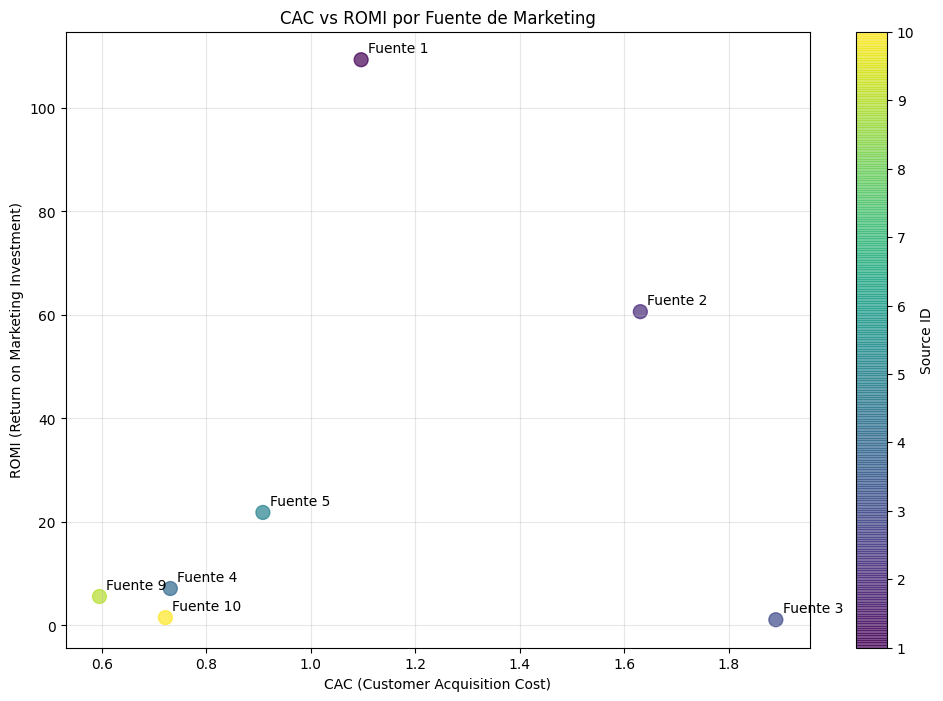

In [ ]:
# Gráfico de dispersión CAC vs ROMI
plt.figure(figsize=(12, 8))
scatter = plt.scatter(cac_data['cac'], cac_data['romi'], 
                     s=100, alpha=0.7, c=cac_data.index, cmap='viridis')

# Agregar etiquetas para cada punto
for i, source in enumerate(cac_data.index):
    plt.annotate(f'Fuente {source}', 
                (cac_data['cac'].iloc[i], cac_data['romi'].iloc[i]),
                xytext=(5, 5), textcoords='offset points')

plt.xlabel('CAC (Customer Acquisition Cost)')
plt.ylabel('ROMI (Return on Marketing Investment)')
plt.title('CAC vs ROMI por Fuente de Marketing')
plt.grid(True, alpha=0.3)
plt.colorbar(scatter, label='Source ID')
plt.show()

In [ ]:
# Calcular ROMI (Return on Marketing Investment)
cac_data['romi'] = (cac_data['revenue'] - cac_data['costs']) / cac_data['costs']
print("ROMI por fuente:")
print(cac_data[['costs', 'revenue', 'romi']].round(2))

ROMI por fuente:
               costs     revenue    romi
source_id                               
1           20833.27  2298200.17  109.31
2           42806.04  2638189.21   60.63
3          141321.63   296687.96    1.10
4           61073.60   496690.17    7.13
5           51757.10  1181477.14   21.83
9            5517.49    36342.25    5.59
10           5822.49    14619.23    1.51


In [ ]:
# Primero, limpiemos el DataFrame cac_data
# Eliminar las columnas duplicadas y mantener solo una columna 'revenue'
cac_data = cac_data.drop(columns=['revenue_x'])
cac_data = cac_data.rename(columns={'revenue_y': 'revenue'})

# Verificar que esté correcto
print("Columnas actuales:")
print(cac_data.columns.tolist())
print("\nDataFrame limpio:")
print(cac_data.head())

Columnas actuales:
['uid', 'costs', 'cac', 'romi', 'revenue']

DataFrame limpio:
             uid      costs       cac        romi       revenue
source_id                                                      
1          18999   20833.27  1.096546  109.313944  2.298200e+06
2          26245   42806.04  1.631017   60.631237  2.638189e+06
3          74756  141321.63  1.890439    1.099381  2.966880e+05
4          83525   61073.60  0.731201    7.132649  4.966902e+05
5          56974   51757.10  0.908434   21.827344  1.181477e+06


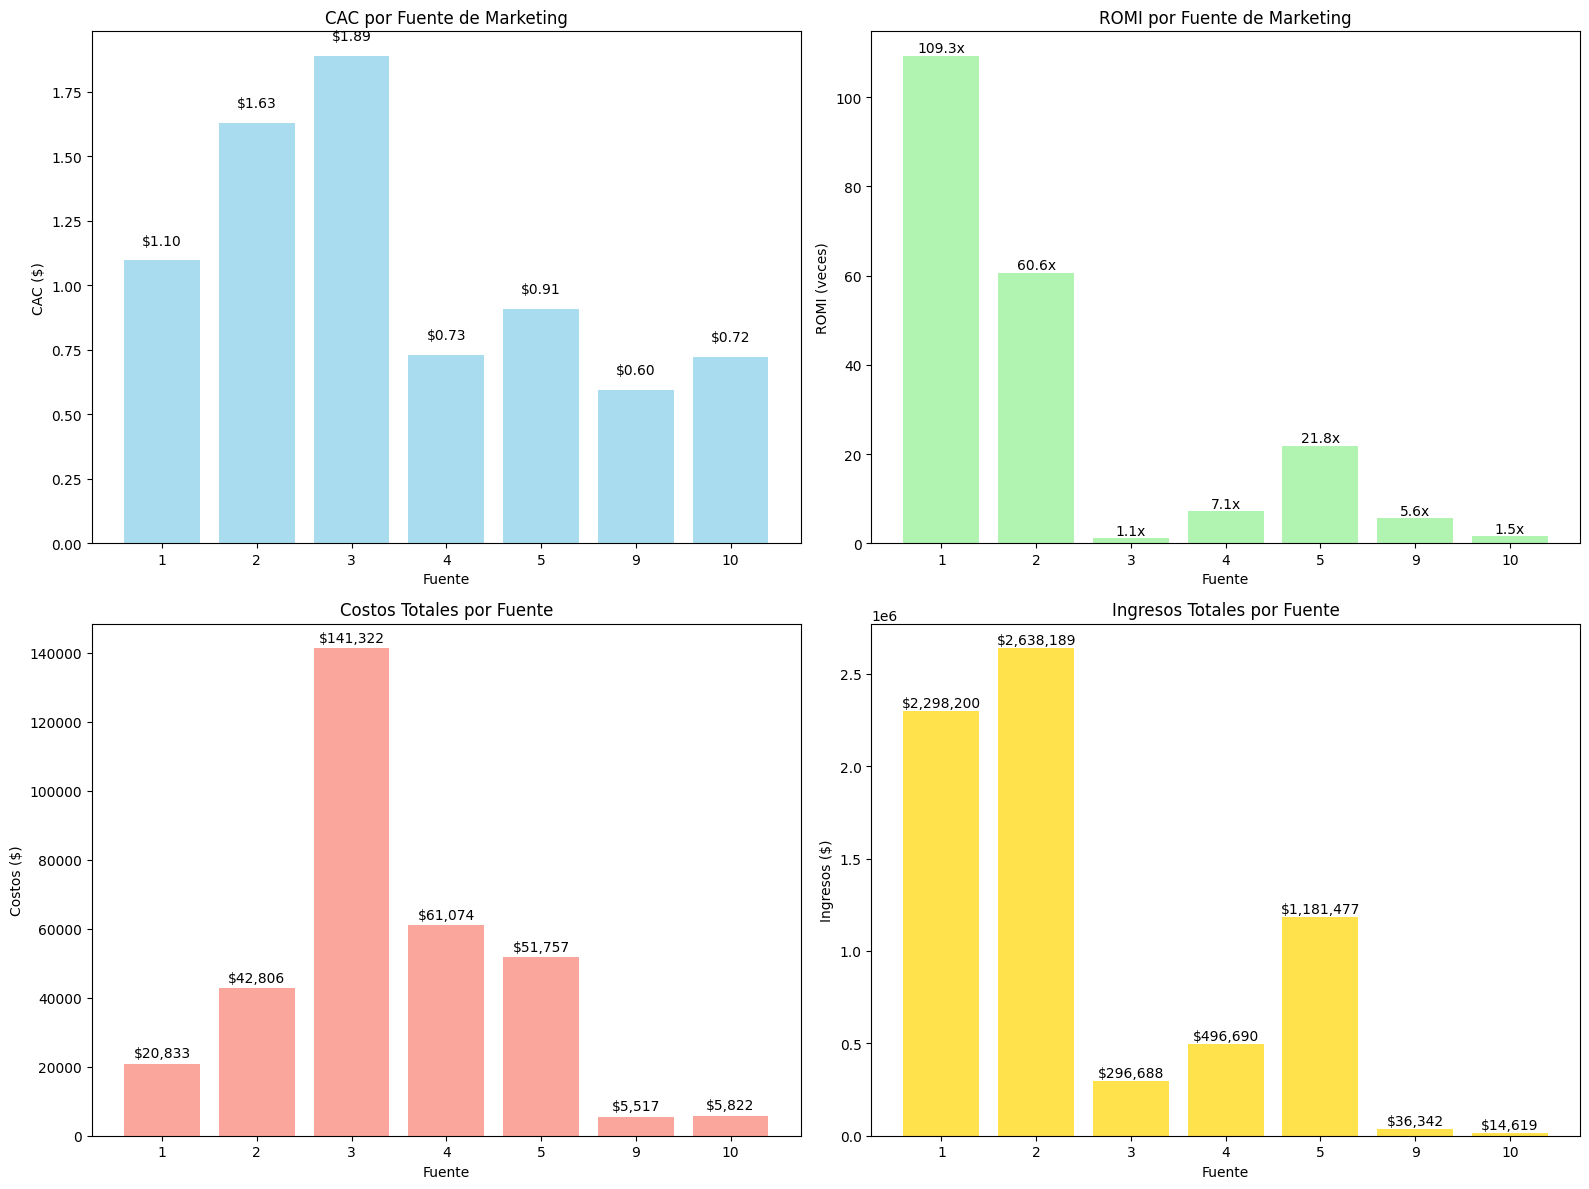

In [ ]:
# Gráfico de distribución por fuentes
fig, axes = plt.subplots(2, 2, figsize=(16, 12))



# 1. Distribución de CAC por fuente
axes[0,0].bar(cac_data.index.astype(str), cac_data['cac'], color='skyblue', alpha=0.7)
axes[0,0].set_title('CAC por Fuente de Marketing')
axes[0,0].set_xlabel('Fuente')
axes[0,0].set_ylabel('CAC ($)')
for i, v in enumerate(cac_data['cac']):
    axes[0,0].text(i, v + 0.05, f'${v:.2f}', ha='center', va='bottom')

# 2. Distribución de ROMI por fuente
axes[0,1].bar(cac_data.index.astype(str), cac_data['romi'], color='lightgreen', alpha=0.7)
axes[0,1].set_title('ROMI por Fuente de Marketing')
axes[0,1].set_xlabel('Fuente')
axes[0,1].set_ylabel('ROMI (veces)')
for i, v in enumerate(cac_data['romi']):
    axes[0,1].text(i, v + 0.1, f'{v:.1f}x', ha='center', va='bottom')

# 3. Distribución de Costos por fuente
axes[1,0].bar(cac_data.index.astype(str), cac_data['costs'], color='salmon', alpha=0.7)
axes[1,0].set_title('Costos Totales por Fuente')
axes[1,0].set_xlabel('Fuente')
axes[1,0].set_ylabel('Costos ($)')
for i, v in enumerate(cac_data['costs']):
    axes[1,0].text(i, v + 1000, f'${v:,.0f}', ha='center', va='bottom')

# 4. Distribución de Ingresos por fuente
axes[1,1].bar(cac_data.index.astype(str), cac_data['revenue'], color='gold', alpha=0.7)
axes[1,1].set_title('Ingresos Totales por Fuente')
axes[1,1].set_xlabel('Fuente')
axes[1,1].set_ylabel('Ingresos ($)')
for i, v in enumerate(cac_data['revenue']):
    axes[1,1].text(i, v + 5000, f'${v:,.0f}', ha='center', va='bottom')

plt.tight_layout()
plt.show()

#### 3.3 
### Curiosamente el canal 3 es el mas caro y el que menos beneficio trae, pero aparece como de los mas efectivos al principio del analisis, Volumen vs Eficiencia, atrae mucho pero con un costo elevado, sus usuarios, compran mucho al principio, pero despues se van.
### Los canales 1 y dos tienen una relacion costo beneficio excelente, ya que ofrecen un costo moderado y una ganancia significativa
### los canales 4 y 5 se mantienen equilibrados y moderados.

## Estrategia sugerida:
### Reasignar presupuesto, y ajustar apara mejorar los canles que tienen verdadero venefio a la compañia, seguir apoyando el canal numero tres pero con un nuevo enfoque, quiza apuntar a beneficios y promociones que aseguren la permanencia y el flujo constante de compra. 

### Sin mas por el momento, quedo a la orden para cualquieer revision.
